In [ ]:
!uv pip install -U langchain langchain_core langchain_community langchain_google_genai tavily-python
# 👉 필요한 라이브러리 설치 (LangChain + Google Gemini + Tavily 검색 툴)

# 💬 LLM + Tool을 이용한 간단한 "고객지원 챗봇" 
- 사용자의 질문 → AI가 필요시 도구 호출 → 결과 반영 → 최종 답변 생성.  
- 즉, **AI + 규칙 + 검색도구 + 맞춤도구**가 합쳐져 고객센터 상담을 자동화하는 구조입니다.

## 단계 1. AI 모델 준비

In [1]:
# Load environment variables in a file called .env
# API 키 설정 
import os
from dotenv import load_dotenv
load_dotenv(override=True)

True

In [2]:
from langchain_core.rate_limiters import InMemoryRateLimiter
from langchain_openai import ChatOpenAI  # LangChain 라이브러리에서 ChatOpenAI 가져오기

# 👉 요청 제한기(Rate Limiter)와 ChatOpenAI 모델 불러오기
# from langchain_openai import ChatOpenAI
# 고객지원 시나리오에서도 동일한 호출 제한 가정 (분당 10회)
request_throttle = InMemoryRateLimiter(
    requests_per_second=0.167,  # 👉 초당 약 0.167회 → 분당 10회 제한
    check_every_n_seconds=0.1,  # 👉 0.1초마다 요청 횟수 체크
    max_bucket_size=10,         # 👉 최대 10개까지 한 번에 처리 가능
)

# Rate Limiter를 적용한 LLM 인스턴스
cs_llm = ChatOpenAI(
    model="gpt-5-mini",  # 👉 사용할 OpenAI 모델 지정
    rate_limiter=request_throttle, # 👉 위에서 만든 요청 제한기 적용
)

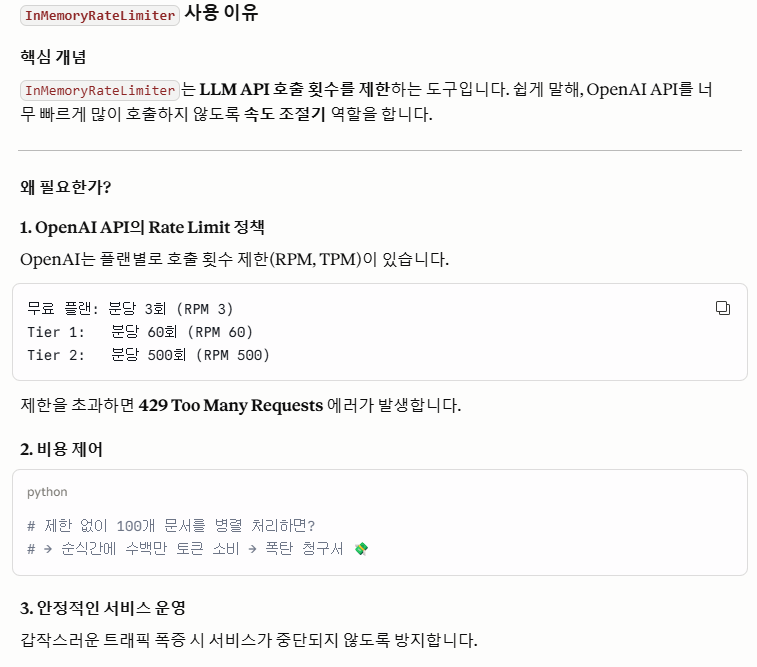

## 외부 검색 도구 연결

In [3]:
from langchain_community.tools.tavily_search import TavilySearchResults  # Tavily 웹 검색 도구
# 👉 외부 검색을 위한 Tavily 툴 불러오기
# 고객지원 검색용 Tavily 인스턴스
support_search = TavilySearchResults(
    max_results=3,            # 👉 검색 최대 3개
    include_answer=True,      # 👉 요약 포함
    include_raw_content=True, # 👉 원문 포함
)

C:\Users\jino7\AppData\Local\Temp\ipykernel_8468\2856698428.py:4: LangChainDeprecationWarning: The class `TavilySearchResults` was deprecated in LangChain 0.3.25 and will be removed in 1.0. An updated version of the class exists in the `langchain-tavily package and should be used instead. To use it run `pip install -U `langchain-tavily` and import as `from `langchain_tavily import TavilySearch``.
  support_search = TavilySearchResults(


## LLM + Tool을 이용한 간단한 "고객지원 에이전트" 함수

In [8]:
from langchain_core.messages import HumanMessage, SystemMessage, AIMessage

# 💬 LLM + Tool을 이용한 간단한 "고객지원 에이전트" 함수
def support_workflow(cs_llm, inquiry, tools=[support_search]):
    # ✅ 1. 사용할 툴들을 이름 기준으로 정리 (딕셔너리 형태)
    support_tool_map = {x.name: x for x in tools}

    # ✅ 2. LLM에 툴 연결 (이제 모델이 툴을 직접 호출할 수 있음)
    cs_llm_with_tools_local = cs_llm.bind_tools(tools)

    # ✅ 3. 사용자 질문 메시지 생성
    dialogs = [HumanMessage(content=inquiry)]
    print(f"📩 사용자 질문: {inquiry}")

    # ✅ 4. LLM이 질문을 받아 '툴이 필요할지' 판단
    tool_decision = cs_llm_with_tools_local.invoke(inquiry)  # Agent 부분: LLM이 "이 질문에는 검색 툴을 써야겠다 / sum_counts를 써야겠다" 등을 판단
    dialogs.append(tool_decision)  # 대화 흐름에 모델 응답 추가

    # ✅ 5. 모든 툴 호출을 순서대로 처리
    if tool_decision.tool_calls:
        for tool_call in tool_decision.tool_calls:  # 👉 모든 툴 호출 순회
            chosen_tool = tool_call['name']
            print(f"🛠️ 툴 실행 요청: {chosen_tool}")
            print("툴 호출 세부 정보:", tool_call)

            # 👉 실제 툴 객체 가져오기
            tool_exec = support_tool_map[chosen_tool]

            # 👉 툴 실행 및 결과를 대화 흐름에 추가
            tool_output = tool_exec.invoke(tool_call)  # 👉 각 호출마다 실행
            dialogs.append(tool_output)                # 👉 각 결과를 대화에 추가

        # ✅ 6. 모든 툴 결과가 쌓인 후 최종 답변 생성
        final_response = cs_llm_with_tools_local.invoke(dialogs)
    else:
        # 🔹 툴이 필요 없는 경우, LLM의 첫 응답이 곧 최종 답변
        final_response = tool_decision

    # ✅ 7. 최종 답변 내용(content)만 반환
    return final_response.content


In [9]:
# 🚀 함수 실행 테스트
answer_text = support_workflow(cs_llm, "최신 유행 옷 트렌드를 검색해줘")
print("🤖 최종 답변:", answer_text)

📩 사용자 질문: 최신 유행 옷 트렌드를 검색해줘
🤖 최종 답변: 어떤 범위로 찾아드릴까요?

간단히 알려주시면 바로 최신 트렌드를 검색해서 요약해 드릴게요.
- 지역: 한국 / 글로벌
- 대상: 여성 / 남성 / 유니섹스
- 시즌: 지금(일반) / 봄여름 / 가을겨울

원하시는 옵션만 알려주세요. 추천 형식(요약 + 핵심 아이템/색상/실루엣 + 쇼핑 또는 레퍼런스 링크)도 선택해 주세요.


## gradio 웹 실행

In [10]:
import gradio as gr

# ✅ Gradio용 래퍼 함수 (기존 support_workflow 호출)
def gradio_support(inquiry):
    return support_workflow(cs_llm, inquiry, tools=[support_search])

# ✅ Gradio UI 구성 및 실행
demo = gr.Interface(
    fn=gradio_support,                        # 👉 실행할 함수
    inputs=gr.Textbox(
        lines=3,
        placeholder="고객 문의를 입력하세요...",
        label="고객 질문"
    ),
    outputs=gr.Textbox(
        lines=10,
        label="에이전트 답변"
    ),
    title="🤖 고객지원 AI 에이전트",
    description="Tavily 검색 툴이 연결된 LLM 기반 고객지원 챗봇입니다.",
    examples=[
        ["최신 아이폰 가격이 얼마인가요?"],
        ["환불 정책이 어떻게 되나요?"],
    ],
    flagging_mode="never",                    # 👉 플래그 버튼 제거
)

# 주피터 노트북에서는 share=False, inline=True 권장
demo.launch(share=False, inline=True)

* Running on local URL:  http://127.0.0.1:7860
* To create a public link, set `share=True` in `launch()`.


📩 사용자 질문: 최신 유행 옷 트렌드를 검색해줘
🛠️ 툴 실행 요청: tavily_search_results_json
툴 호출 세부 정보: {'name': 'tavily_search_results_json', 'args': {'query': "2026 fashion trends summer 2026 clothing trends latest '2026' 'fashion trends' 'summer'"}, 'id': 'call_N9SzQVZYdUf44amSPvr1lyXy', 'type': 'tool_call'}
🛠️ 툴 실행 요청: tavily_search_results_json
툴 호출 세부 정보: {'name': 'tavily_search_results_json', 'args': {'query': '2026 Korean fashion trends 한국 패션 트렌드 2026 스트리트웨어 트렌드'}, 'id': 'call_3xVAvzWsBkm6OWhEu8G3QyvY', 'type': 'tool_call'}
🛠️ 툴 실행 요청: tavily_search_results_json
툴 호출 세부 정보: {'name': 'tavily_search_results_json', 'args': {'query': "spring summer 2026 runway trends Vogue Business of Fashion WWD runway report '2026' 'SS26' trends"}, 'id': 'call_Sk9QxsNu6nptNsG29t3a3Ztj', 'type': 'tool_call'}
🛠️ 툴 실행 요청: tavily_search_results_json
툴 호출 세부 정보: {'name': 'tavily_search_results_json', 'args': {'query': "sustainable fashion trends 2026 circular fashion upcycling '2026 fashion' 'sustainability' trends"}, 'id': '